## Gastric cancer

In [1]:
import pandas as pd
import os

In [2]:
# 加载数据集
file_path = '../ELIFE pancancer ready-to-use data.csv'
data = pd.read_csv(file_path)

In [3]:
positive_samples = data[data['Diagnosis'] == "Gastric cancer"]
negative_samples = data[data['Label'] == 0]

num_negative = len(positive_samples) * 2  # 负样本数量是正样本的 2 倍
negative_samples = negative_samples.sample(n=num_negative, random_state=42)  # 随机采样负样本
positive_samples_upsampled = positive_samples.sample(n=len(positive_samples)*2, replace=True, random_state=42)

# 合并正负样本
Gastric_sample = pd.concat([positive_samples_upsampled, negative_samples], ignore_index=True)
Gastric_sample = Gastric_sample.drop(columns=["SampleID", "Cohort", "Diagnosis"])
Gastric_sample.to_csv("Gastric_sample.csv", index=False)

In [4]:
Gastric_data = pd.read_csv("Gastric_sample.csv")
Gastric_data

,Label,TMD_1,TMD_2,TMD_3,TMD_4,TMD_5,TMD_6,TMD_7,TMD_8,TMD_9,...,MOTIF_END_TTCG,MOTIF_END_TTCT,MOTIF_END_TTGA,MOTIF_END_TTGC,MOTIF_END_TTGG,MOTIF_END_TTGT,MOTIF_END_TTTA,MOTIF_END_TTTC,MOTIF_END_TTTG,MOTIF_END_TTTT
0,1,0.984642,0.055988,0.018028,0.048551,0.866213,0.916667,0.956522,0.188540,0.178971,...,0.000420,0.004607,0.004013,0.002667,0.003709,0.003764,0.006087,0.005161,0.005029,0.008751
1,1,0.993631,0.014084,0.045627,0.012195,0.886364,0.914894,1.000000,0.196078,0.155172,...,0.000427,0.004723,0.004077,0.002715,0.003521,0.003850,0.006074,0.005133,0.005119,0.009034
2,1,0.960684,0.064650,0.052937,0.074099,0.897707,0.900000,0.963636,0.390710,0.242424,...,0.000362,0.004510,0.003986,0.002478,0.003227,0.003542,0.005966,0.004870,0.004608,0.008509
3,1,0.937500,0.115385,0.031621,0.066406,0.981707,0.940299,1.000000,0.106667,0.125561,...,0.000384,0.004679,0.004058,0.002643,0.003497,0.003818,0.006149,0.005082,0.004895,0.008967
4,1,0.932584,0.071161,0.065336,0.051613,0.962025,1.000000,0.833333,0.188889,0.090909,...,0.000398,0.004584,0.003942,0.002604,0.003404,0.003692,0.005768,0.004915,0.004695,0.008499
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387,0,0.958810,0.097778,0.047214,0.068655,0.967822,0.951724,0.976190,0.255965,0.169620,...,0.000386,0.004561,0.003899,0.002572,0.003220,0.003635,0.005953,0.004903,0.004684,0.008603
388,0,0.990991,0.071429,0.044657,0.098859,0.949495,0.945736,1.000000,0.385542,0.188172,...,0.000392,0.004192,0.004038,0.002426,0.003719,0.003559,0.005715,0.004438,0.004809,0.007844
389,0,0.987654,0.111111,0.000000,0.061947,0.978723,0.952381,1.000000,0.200000,0.153846,...,0.000396,0.004552,0.004013,0.002606,0.003455,0.003719,0.005949,0.004918,0.004784,0.008593
390,0,1.000000,0.103448,0.119403,0.113821,0.888889,0.724138,0.952381,0.230769,0.158537,...,0.000396,0.004350,0.004155,0.002505,0.003536,0.003659,0.005849,0.004658,0.004887,0.008030


### Fscore

In [93]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Gastric_sample_FscoreSorted.csv"
data = pd.read_csv(file_path)

In [94]:
data

,class,MOTIF_END_CAAA,MOTIF_END_CAAC,MOTIF_END_CAAT,MOTIF_END_TGCA,MOTIF_END_TGCG,MOTIF_END_TGGT,MOTIF_END_CAAG,MOTIF_END_GGCT,MOTIF_END_TGGC,...,GWFP_ratio_17:70000001-75000000,CNA_5:86000001-87000000,GWFP_long_12:20000001-25000000,CNA_4:167000001-168000000,CNA_1:32000001-33000000,GWFP_long_17:10000001-15000000,TMD_435,TMD_292,CNA_18:73000001-74000000,GWMD_chr4_64
0,1,0.008928,0.003598,0.004958,0.004742,0.000788,0.003659,0.006219,0.003667,0.003960,...,0.320758,0.993853,0.493711,1.007180,0.893604,0.248256,0.932551,0.874502,0.957837,0.872565
1,1,0.008755,0.003365,0.004841,0.005348,0.000798,0.004056,0.005992,0.004013,0.004084,...,0.244201,1.097440,0.432085,1.041480,0.993825,0.777005,0.976378,0.862595,0.969485,0.833710
2,1,0.010346,0.003763,0.005673,0.004737,0.000610,0.003502,0.006533,0.003642,0.003509,...,0.325416,0.999492,0.519711,1.007670,1.017440,0.407986,0.915160,0.884283,0.929445,0.803922
3,1,0.009477,0.003405,0.005128,0.005244,0.000785,0.003998,0.006376,0.003943,0.003952,...,0.270870,1.049280,0.556501,1.030240,0.930342,0.361800,0.953846,0.743017,0.983834,0.840650
4,1,0.008567,0.003362,0.004773,0.005297,0.000832,0.003953,0.006126,0.004548,0.004130,...,0.226725,1.100820,0.534977,0.961728,0.924452,0.518809,0.895833,0.872340,0.975452,0.809025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387,0,0.009388,0.003449,0.005187,0.005126,0.000744,0.003830,0.006104,0.004044,0.003890,...,0.336372,1.054300,0.681987,0.993974,0.921712,0.527398,0.941176,0.933941,0.936578,0.832653
388,0,0.008910,0.003275,0.004596,0.005065,0.000869,0.003856,0.006670,0.004115,0.004020,...,0.205757,1.043960,0.476578,1.042060,0.940648,0.456351,0.982249,0.893939,0.973840,0.799696
389,0,0.009084,0.003380,0.005006,0.005094,0.000783,0.003971,0.006401,0.004165,0.004129,...,0.287841,1.040300,0.501491,1.029640,0.954621,0.553405,0.957447,0.898551,0.926365,0.827154
390,0,0.009268,0.003265,0.004900,0.005405,0.000813,0.003992,0.006585,0.004101,0.004015,...,0.254503,0.999446,0.512601,1.003570,0.970516,0.690605,0.939024,0.921053,0.974968,0.837763


In [95]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [103]:
all_features = X_train.columns.tolist()
auc_train_scores_Fscore = []
auc_val_scores_Fscore = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [104]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_Fscore.append(auc_train)
    auc_val_scores_Fscore.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >=30:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
验证集 AUC 开始下降（0.8866 → 0.8584），连续次数：1
{4}
{5}
验证集 AUC 开始下降（0.9224 → 0.8805），连续次数：1
{6}
{7}
验证集 AUC 开始下降（0.8972 → 0.8906），连续次数：1
{8}
{9}
{10}
验证集 AUC 开始下降（0.9219 → 0.8805），连续次数：1
{11}
验证集 AUC 开始下降（0.8805 → 0.8725），连续次数：2
{12}
{13}
{14}
验证集 AUC 开始下降（0.9093 → 0.9042），连续次数：1
{15}
{16}
验证集 AUC 开始下降（0.9279 → 0.9098），连续次数：1
{17}
{18}
验证集 AUC 开始下降（0.9345 → 0.9219），连续次数：1
{19}
{20}
{21}
验证集 AUC 开始下降（0.9501 → 0.9446），连续次数：1
{22}
验证集 AUC 开始下降（0.9446 → 0.9380），连续次数：2
{23}
验证集 AUC 开始下降（0.9380 → 0.9219），连续次数：3
{24}
{25}
验证集 AUC 开始下降（0.9456 → 0.9425），连续次数：1
{26}
验证集 AUC 开始下降（0.9425 → 0.9400），连续次数：2
{27}
验证集 AUC 开始下降（0.9400 → 0.8911），连续次数：3
{28}
{29}
验证集 AUC 开始下降（0.9148 → 0.9138），连续次数：1
{30}
选择的特征数: 20, 最佳验证集 AUC: 0.9501, 对应的训练集 AUC：0.9640


In [114]:
Gastric_sample_FscoreSorted = pd.read_csv("Gastric_sample_FscoreSorted.csv")
Gastric_sample_FscoreSorted_selected20 = Gastric_sample_FscoreSorted.iloc[:, :21]
Gastric_sample_FscoreSorted_selected20.to_csv("../Fscore/Gastric_sample_FscoreSorted_selected20.csv", index=False)

In [105]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Fscore) + 1),
    "Train_AUC": auc_train_scores_Fscore,
    "Validation_AUC": auc_val_scores_Fscore
})

auc_df.to_csv("AUC_scores_Fscore.csv", index=False)

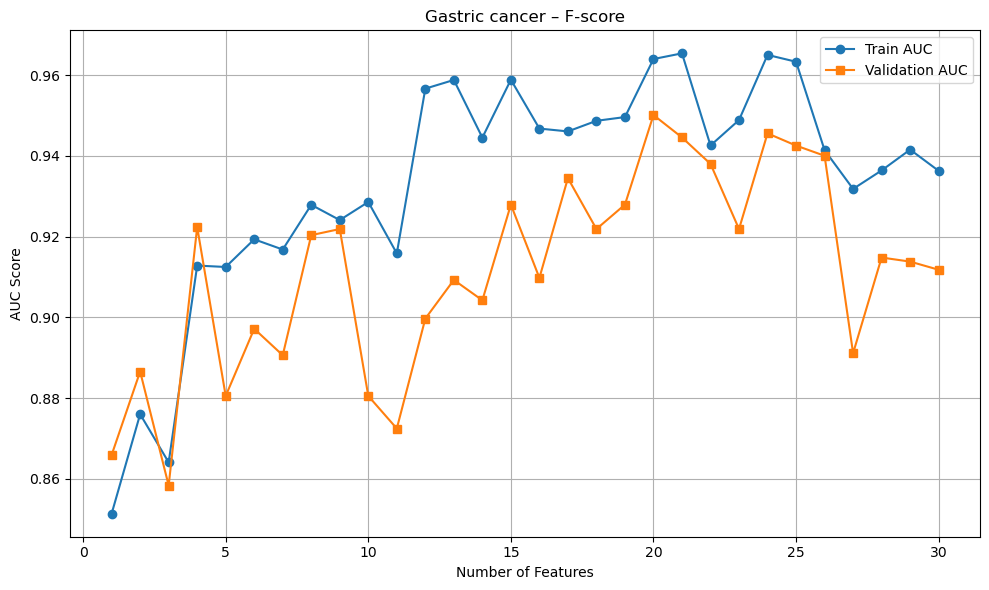

In [134]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Fscore.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Gastric cancer – F-score")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Fscore.png", dpi=300)
plt.show()


### ANOVA

In [85]:
import pandas as pd

# 1. 读取最终的 CSV 文件
csv_file = "Gastric_sample_AnovaSorted.csv"
df = pd.read_csv(csv_file)

# 2. 读取 ANOVA 排序的特征文件，获取正确的特征名顺序
anova_sorted_file = "../ANOVA/Gastric_feature_importance.csv" 
with open(anova_sorted_file, "r") as f:
    sorted_feature_names = [line.split()[1] for line in f.readlines()]  # 取出特征名称

# 3. 获取当前 CSV 文件的列名（去掉第一列 class）
original_column_names = list(df.columns[1:])  # 去掉第 1 列类别标签

# 4. 创建新的列名列表（保持类别标签不变）
new_column_names = ["class"] + sorted_feature_names[:len(original_column_names)]

# 5. 重新设置 DataFrame 的列名
df.columns = new_column_names

# 6. 保存修改后的 CSV 文件
df.to_csv("Gastric_sample_AnovaSorted_corrected.csv", index=False)


In [107]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Gastric_sample_AnovaSorted_corrected.csv"
data = pd.read_csv(file_path)

In [108]:
data

,class,MOTIF_END_CAAA,MOTIF_END_CAAC,MOTIF_END_CAAT,MOTIF_END_TGCA,MOTIF_END_TGCG,MOTIF_END_TGGT,MOTIF_END_CAAG,MOTIF_END_GGCT,MOTIF_END_TGGC,...,GWFP_ratio_17:70000001-75000000,CNA_5:86000001-87000000,GWFP_long_12:20000001-25000000,CNA_4:167000001-168000000,CNA_1:32000001-33000000,GWFP_long_17:10000001-15000000,TMD_435,TMD_292,CNA_18:73000001-74000000,GWMD_chr4_64
0,1,0.008928,0.003598,0.004958,0.004742,0.000788,0.003659,0.006219,0.003667,0.003960,...,0.320758,0.993853,0.493711,1.007180,0.893604,0.248256,0.932551,0.874502,0.957837,0.872565
1,1,0.008755,0.003365,0.004841,0.005348,0.000798,0.004056,0.005992,0.004013,0.004084,...,0.244201,1.097440,0.432085,1.041480,0.993825,0.777005,0.976378,0.862595,0.969485,0.833710
2,1,0.010346,0.003763,0.005673,0.004737,0.000610,0.003502,0.006533,0.003642,0.003509,...,0.325416,0.999492,0.519711,1.007670,1.017440,0.407986,0.915160,0.884283,0.929445,0.803922
3,1,0.009477,0.003405,0.005128,0.005244,0.000785,0.003998,0.006376,0.003943,0.003952,...,0.270870,1.049280,0.556501,1.030240,0.930342,0.361800,0.953846,0.743017,0.983834,0.840650
4,1,0.008567,0.003362,0.004773,0.005297,0.000832,0.003953,0.006126,0.004548,0.004130,...,0.226725,1.100820,0.534977,0.961728,0.924452,0.518809,0.895833,0.872340,0.975452,0.809025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387,0,0.009388,0.003449,0.005187,0.005126,0.000744,0.003830,0.006104,0.004044,0.003890,...,0.336372,1.054300,0.681987,0.993974,0.921712,0.527398,0.941176,0.933941,0.936578,0.832653
388,0,0.008910,0.003275,0.004596,0.005065,0.000869,0.003856,0.006670,0.004115,0.004020,...,0.205757,1.043960,0.476578,1.042060,0.940648,0.456351,0.982249,0.893939,0.973840,0.799696
389,0,0.009084,0.003380,0.005006,0.005094,0.000783,0.003971,0.006401,0.004165,0.004129,...,0.287841,1.040300,0.501491,1.029640,0.954621,0.553405,0.957447,0.898551,0.926365,0.827154
390,0,0.009268,0.003265,0.004900,0.005405,0.000813,0.003992,0.006585,0.004101,0.004015,...,0.254503,0.999446,0.512601,1.003570,0.970516,0.690605,0.939024,0.921053,0.974968,0.837763


In [109]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [110]:
all_features = X_train.columns.tolist()
auc_train_scores_ANOVA = []
auc_val_scores_ANOVA = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1  
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [111]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_ANOVA.append(auc_train)
    auc_val_scores_ANOVA.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >=30:
        break
    
    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
验证集 AUC 开始下降（0.8866 → 0.8584），连续次数：1
{4}
{5}
验证集 AUC 开始下降（0.9224 → 0.8805），连续次数：1
{6}
{7}
验证集 AUC 开始下降（0.8972 → 0.8906），连续次数：1
{8}
{9}
{10}
验证集 AUC 开始下降（0.9219 → 0.8805），连续次数：1
{11}
验证集 AUC 开始下降（0.8805 → 0.8725），连续次数：2
{12}
{13}
{14}
验证集 AUC 开始下降（0.9093 → 0.9042），连续次数：1
{15}
{16}
验证集 AUC 开始下降（0.9279 → 0.9098），连续次数：1
{17}
{18}
验证集 AUC 开始下降（0.9345 → 0.9219），连续次数：1
{19}
{20}
{21}
验证集 AUC 开始下降（0.9501 → 0.9446），连续次数：1
{22}
验证集 AUC 开始下降（0.9446 → 0.9380），连续次数：2
{23}
验证集 AUC 开始下降（0.9380 → 0.9219），连续次数：3
{24}
{25}
验证集 AUC 开始下降（0.9456 → 0.9425），连续次数：1
{26}
验证集 AUC 开始下降（0.9425 → 0.9400），连续次数：2
{27}
验证集 AUC 开始下降（0.9400 → 0.8911），连续次数：3
{28}
{29}
验证集 AUC 开始下降（0.9148 → 0.9138），连续次数：1
{30}
选择的特征数: 20, 最佳验证集 AUC: 0.9501, 对应的训练集 AUC：0.9640


In [115]:
Gastric_sample_AnovaSorted_corrected = pd.read_csv("Gastric_sample_AnovaSorted_corrected.csv")
Gastric_sample_AnovaSorted_selected20 = Gastric_sample_AnovaSorted_corrected.iloc[:, :21]
Gastric_sample_AnovaSorted_selected20.to_csv("../ANOVA/Gastric_sample_AnovaSorted_selected20.csv", index=False)

In [112]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ANOVA) + 1),
    "Train_AUC": auc_train_scores_ANOVA,
    "Validation_AUC": auc_val_scores_ANOVA
})

auc_df.to_csv("AUC_scores_ANOVA.csv", index=False)

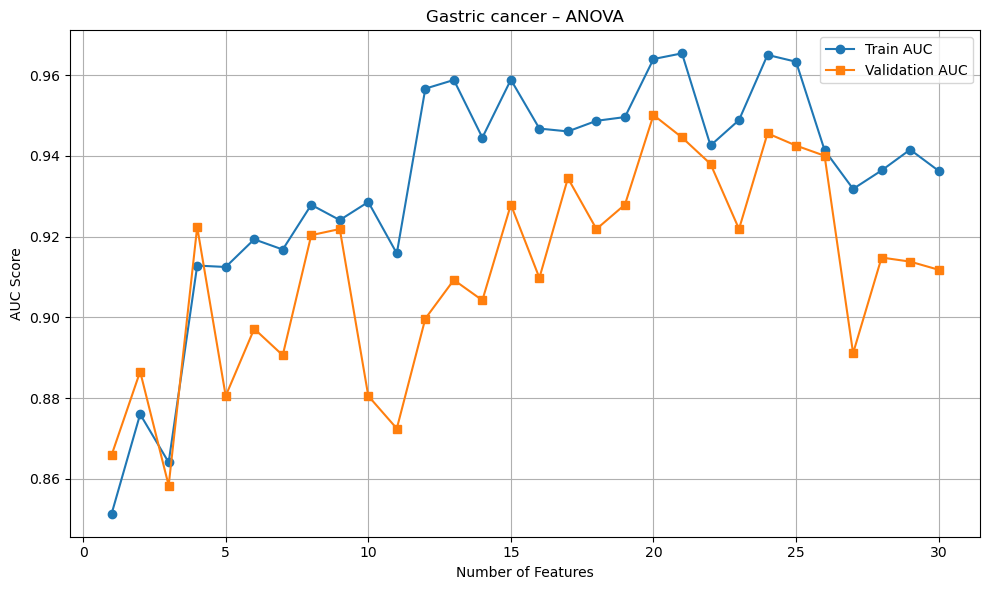

In [135]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ANOVA.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Gastric cancer – ANOVA")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_ANOVA.png", dpi=300)
plt.show()


### ReliefF

In [116]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Gastric_sample_ReliefFSorted.csv"
data = pd.read_csv(file_path)

In [117]:
data


,class,MOTIF_END_CAAA,MOTIF_END_TGCA,MOTIF_END_TGAC,MOTIF_END_TGAT,MOTIF_END_CAAT,MOTIF_END_TGCC,MOTIF_END_CAAG,MOTIF_END_TGCT,MOTIF_END_CATG,...,CNA_7:117000001-118000000,GWMD_chr3_179,TMD_178,TMD_148,TMD_160,CNA_8:128000001-129000000,CNA_8:17000001-18000000,TMD_342,TMD_334,TMD_137
0,1,0.008928,0.004742,0.003241,0.004219,0.004958,0.003285,0.006219,0.004254,0.005944,...,1.10518,0.794643,0.026047,0.894737,0.022613,1.027820,1.08538,0.011823,0.009366,0.008197
1,1,0.008755,0.005348,0.003630,0.004810,0.004841,0.003584,0.005992,0.004788,0.005990,...,1.06568,0.807085,0.052448,1.000000,0.000000,1.028120,1.03998,0.008065,0.000000,0.000000
2,1,0.010346,0.004737,0.003330,0.004542,0.005673,0.002969,0.006533,0.004030,0.006089,...,1.07003,0.819913,0.043134,0.916667,0.122563,1.036460,1.06459,0.019435,0.025610,0.018727
3,1,0.009477,0.005244,0.003454,0.004748,0.005128,0.003347,0.006376,0.004611,0.005895,...,1.09040,0.833005,0.020231,0.750000,0.054264,1.010350,1.11527,0.034091,0.027027,0.020833
4,1,0.008567,0.005297,0.003602,0.004722,0.004773,0.003695,0.006126,0.004872,0.005980,...,1.06664,0.792913,0.022472,0.818182,0.017699,1.042200,1.11570,0.000000,0.009740,0.046875
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387,0,0.009388,0.005126,0.003446,0.004709,0.005187,0.003390,0.006104,0.004671,0.006043,...,1.09366,0.808986,0.029206,0.916667,0.034091,1.033740,1.04950,0.022680,0.027397,0.037037
388,0,0.008910,0.005065,0.003439,0.004390,0.004596,0.002979,0.006670,0.003941,0.006330,...,1.15640,0.776190,0.030011,1.000000,0.002551,1.028540,1.09894,0.103896,0.054054,0.000000
389,0,0.009084,0.005094,0.003553,0.004627,0.005006,0.003268,0.006401,0.004452,0.005971,...,1.08711,0.852817,0.042484,1.000000,0.051546,1.049340,1.12439,0.114286,0.000000,0.000000
390,0,0.009268,0.005405,0.003590,0.004946,0.004900,0.003352,0.006585,0.004441,0.006321,...,1.04149,0.835568,0.030556,1.000000,0.571429,1.003180,1.09617,0.000000,0.093023,0.000000


In [118]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [119]:
all_features = X_train.columns.tolist()
auc_train_scores_ReliefF = []
auc_val_scores_ReliefF = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.2
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [120]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_ReliefF.append(auc_train)
    auc_val_scores_ReliefF.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >=40:
        break
    
    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
{4}
验证集 AUC 开始下降（0.9068 → 0.8926），连续次数：1
{5}
验证集 AUC 开始下降（0.8926 → 0.8881），连续次数：2
{6}
{7}
验证集 AUC 开始下降（0.9410 → 0.9052），连续次数：1
{8}
{9}
验证集 AUC 开始下降（0.9088 → 0.8886），连续次数：1
{10}
{11}
验证集 AUC 开始下降（0.9183 → 0.9022），连续次数：1
{12}
{13}
{14}
{15}
验证集 AUC 开始下降（0.9385 → 0.9234），连续次数：1
{16}
验证集 AUC 开始下降（0.9234 → 0.9143），连续次数：2
{17}
{18}
{19}
验证集 AUC 开始下降（0.9325 → 0.9284），连续次数：1
{20}
验证集 AUC 开始下降（0.9284 → 0.9284），连续次数：2
{21}
{22}
{23}
{24}
验证集 AUC 开始下降（0.9516 → 0.9476），连续次数：1
{25}
{26}
验证集 AUC 开始下降（0.9506 → 0.9496），连续次数：1
{27}
{28}
验证集 AUC 开始下降（0.9677 → 0.9385），连续次数：1
{29}
{30}
验证集 AUC 开始下降（0.9435 → 0.9375），连续次数：1
{31}
{32}
{33}
验证集 AUC 开始下降（0.9577 → 0.9345），连续次数：1
{34}
{35}
验证集 AUC 开始下降（0.9516 → 0.9415），连续次数：1
{36}
{37}
{38}
验证集 AUC 开始下降（0.9516 → 0.9456），连续次数：1
{39}
{40}
选择的特征数: 27, 最佳验证集 AUC: 0.9677, 对应的训练集 AUC：0.9731


In [123]:
Gastric_sample_ReliefFSorted = pd.read_csv("Gastric_sample_ReliefFSorted.csv")
Gastric_sample_ReliefFSorted_selected27 = Gastric_sample_ReliefFSorted.iloc[:, :28]
Gastric_sample_ReliefFSorted_selected27.to_csv("../ReliefF/Gastric_sample_ReliefFSorted_selected27.csv", index=False)

In [121]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ReliefF) + 1),
    "Train_AUC": auc_train_scores_ReliefF,
    "Validation_AUC": auc_val_scores_ReliefF
})

auc_df.to_csv("AUC_scores_ReliefF.csv", index=False)

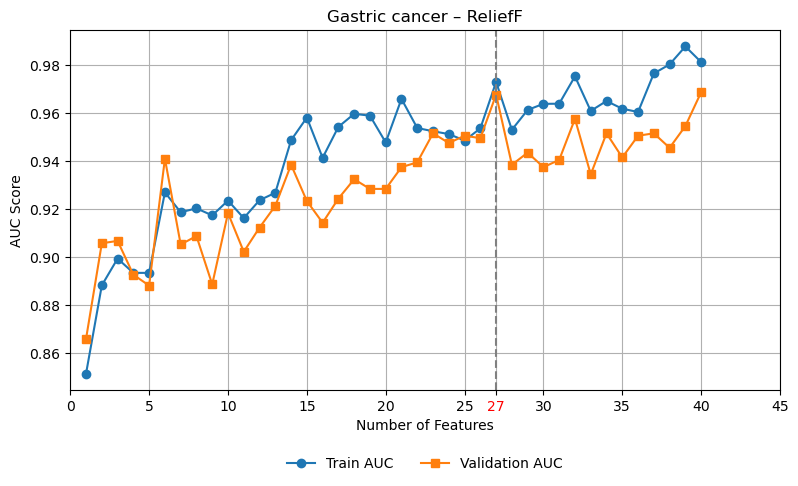

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ReliefF.csv")

# 绘制图像
plt.figure(figsize=(8, 5))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Gastric cancer – ReliefF")
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.grid(True)
plt.tight_layout()

# 添加竖线标注特征数 = 27
plt.axvline(x=27, color='gray', linestyle='--', linewidth=1.5)

# 设置 x 轴刻度并强制包含 27
xticks = sorted(set(plt.xticks()[0].tolist() + [27]))
plt.xticks(xticks)

# 获取坐标轴并标红 27
ax = plt.gca()
for label in ax.get_xticklabels():
    if label.get_text() == '27':
        label.set_color('red')

ax.set_xlim(left=0, right=max(auc_df["Num_Features"]) + 5)

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_ReliefF.png", dpi=300)
plt.show()


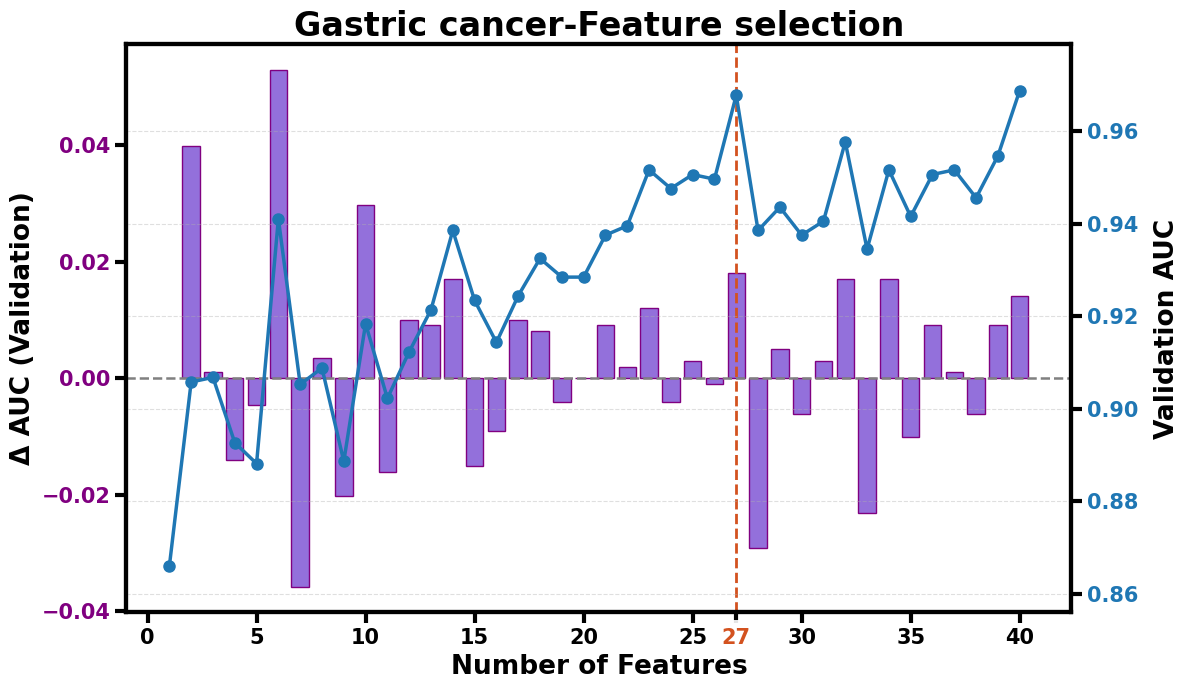

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取数据
auc_df = pd.read_csv("AUC_scores_ReliefF.csv")

# 计算增量
auc_df['Delta_Val_AUC'] = auc_df['Validation_AUC'].diff()

# 绘图
fig, ax1 = plt.subplots(figsize=(12, 7))

# 柱状图：增量 AUC
bars = ax1.bar(auc_df["Num_Features"], auc_df["Delta_Val_AUC"], color='#9370db', edgecolor='purple')
ax1.axhline(0, color='gray', linestyle='--', linewidth=1.8)
ax1.set_xlabel("Number of Features", fontsize=19, fontweight='bold')
ax1.set_ylabel("Δ AUC (Validation)", fontsize=19, color='black', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='purple')

# 添加竖线标注特征数 = 119
plt.axvline(x=27, color='#d3521f', linestyle='--', linewidth=2)

# 设置 x 轴刻度并强制包含 119
xticks = sorted(set(plt.xticks()[0].tolist() + [27]))
plt.xticks(xticks)

# 调整标签位置
ax = plt.gca()
for label in ax.get_xticklabels():
    text = label.get_text()
    if text == '27':
        # 向左微调0.3个单位，设置右对齐
        # label.set_x(label.get_position()[0])
        # label.set_horizontalalignment('right')
        label.set_color('#d3521f')
        label.set_bbox({'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'})
    # elif text == '120':
    #     # 向右微调0.3个单位，设置左对齐
    #     label.set_x(label.get_position()[0])
    #     label.set_horizontalalignment('left')
    #     label.set_bbox({'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'})

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

# 第二轴：叠加 Validation AUC 折线图
ax2 = ax1.twinx()
ax2.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], color='#1f77b4', marker='o', markersize=8, linewidth=2.5, label='Validation AUC')
ax2.set_ylabel("Validation AUC", fontsize=19, color='black', fontweight='bold', labelpad=11)
ax2.tick_params(axis='y', labelcolor='#1f77b4')
ax2.set_ylim(auc_df["Validation_AUC"].min() - 0.01, auc_df["Validation_AUC"].max() + 0.01)

# 图例
# fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.95), frameon=False)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

# 美化
plt.title("Gastric cancer-Feature selection", fontsize=24, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()

# 保存
plt.savefig("DeltaAUC_and_Trend_Highlight27.png", dpi=300)
plt.show()


### Binomial

In [126]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Gastric_sample_BinomialSorted.csv"
data = pd.read_csv(file_path)

In [127]:
data

,class,CNA_1:6000001-7000000,CNA_1:7000001-8000000,CNA_1:17000001-18000000,CNA_1:27000001-28000000,CNA_1:86000001-87000000,CNA_1:100000001-101000000,CNA_1:102000001-103000000,CNA_1:104000001-105000000,CNA_1:115000001-116000000,...,GWMD_chr2_24,GWMD_chr2_126,GWMD_chr4_105,GWMD_chr6_116,GWMD_chr11_91,GWMD_chr17_43,GWMD_chr18_16,GWMD_chr20_13,MOTIF_END_CCAC,GWMD_chr1_122
0,1,0.881596,1.06325,1.05657,0.836884,1.013100,0.848591,0.961164,1.10048,0.528462,...,0.796949,0.838860,0.795337,0.833722,0.850467,0.638642,0.727564,0.846303,0.005451,0.780863
1,1,0.912000,1.06695,1.10797,0.946539,1.006600,0.755614,0.936816,1.02967,0.487284,...,0.809243,0.797560,0.811685,0.808290,0.832685,0.737334,0.690244,0.812200,0.004896,0.759268
2,1,0.920303,1.00627,1.16020,0.963658,1.051270,0.742843,0.954262,1.04759,0.501535,...,0.848269,0.829324,0.850078,0.802960,0.824004,0.759006,0.717122,0.813639,0.004890,0.767988
3,1,0.912433,1.07597,1.08746,0.916358,0.980031,0.814046,0.983217,1.12128,0.518701,...,0.838419,0.830102,0.810811,0.816123,0.836352,0.737316,0.720339,0.826972,0.005047,0.783889
4,1,0.911057,1.06921,1.11524,0.894100,0.987262,0.852610,0.994180,1.11621,0.516136,...,0.776340,0.830370,0.809405,0.791581,0.798778,0.642262,0.656250,0.819485,0.005082,0.742326
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387,0,0.886443,1.02390,1.14538,0.955516,1.030750,0.810855,0.982365,1.07381,0.512767,...,0.809034,0.824708,0.811061,0.813858,0.815708,0.731878,0.672701,0.817806,0.004643,0.742501
388,0,0.913601,1.06830,1.06097,0.923917,1.012010,0.853554,0.987716,1.13937,0.527731,...,0.814227,0.819789,0.816044,0.804360,0.815157,0.675785,0.702146,0.820663,0.004971,0.746114
389,0,0.903836,1.03913,1.08846,0.908225,1.013510,0.844099,0.961863,1.06492,0.500511,...,0.828996,0.809546,0.839867,0.804911,0.820189,0.772241,0.669073,0.820236,0.005030,0.766618
390,0,0.960888,1.04953,1.06731,0.957464,0.989215,0.799037,0.987393,1.02365,0.504864,...,0.830590,0.829053,0.820343,0.805970,0.843963,0.754772,0.711701,0.845507,0.004755,0.764081


In [128]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [129]:
all_features = X_train.columns.tolist()
auc_train_scores_Binomial = []
auc_val_scores_Binomial = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.25
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 30
max_decline_tolerance = 5

In [130]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_Binomial.append(auc_train)
    auc_val_scores_Binomial.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >200:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
验证集 AUC 开始下降（0.7339 → 0.7142），连续次数：1
{3}
验证集 AUC 开始下降（0.7142 → 0.6431），连续次数：2
{4}
{5}
验证集 AUC 开始下降（0.7036 → 0.6845），连续次数：1
{6}
{7}
验证集 AUC 开始下降（0.6996 → 0.6804），连续次数：1
{8}
{9}
{10}
{11}
验证集 AUC 开始下降（0.7409 → 0.7268），连续次数：1
{12}
验证集 AUC 开始下降（0.7268 → 0.7152），连续次数：2
{13}
{14}
验证集 AUC 开始下降（0.7500 → 0.7324），连续次数：1
{15}
验证集 AUC 开始下降（0.7324 → 0.7298），连续次数：2
{16}
{17}
验证集 AUC 开始下降（0.7460 → 0.7339），连续次数：1
{18}
{19}
验证集 AUC 开始下降（0.7611 → 0.7500），连续次数：1
{20}
{21}
验证集 AUC 开始下降（0.7752 → 0.7692），连续次数：1
{22}
{23}
{24}
验证集 AUC 开始下降（0.8145 → 0.8004），连续次数：1
{25}
{26}
验证集 AUC 开始下降（0.8185 → 0.8065），连续次数：1
{27}
验证集 AUC 开始下降（0.8065 → 0.7812），连续次数：2
{28}
验证集 AUC 开始下降（0.7812 → 0.7339），连续次数：3
{29}
{30}
验证集 AUC 开始下降（0.8165 → 0.8075），连续次数：1
{31}
验证集 AUC 开始下降（0.8075 → 0.7923），连续次数：2
{32}
{33}
{34}
验证集 AUC 开始下降（0.7984 → 0.7893），连续次数：1
{35}
{36}
{37}
{38}
验证集 AUC 开始下降（0.8558 → 0.8427），连续次数：1
{39}
验证集 AUC 开始下降（0.8427 → 0.8145），连续次数：2
{40}
{41}
验证集 AUC 开始下降（0.8720 → 0.8216），连续次数：1
{42}
验证集 AUC 开始下降（0.8216 → 

In [133]:
Gastric_sample_BinomialSorted = pd.read_csv("Gastric_sample_BinomialSorted.csv")
Gastric_sample_BinomialSorted_selected74 = Gastric_sample_BinomialSorted.iloc[:, :75]
Gastric_sample_BinomialSorted_selected74.to_csv("../Binomial/Gastric_sample_BinomialSorted_selected74.csv", index=False)

In [131]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Binomial) + 1),
    "Train_AUC": auc_train_scores_Binomial,
    "Validation_AUC": auc_val_scores_Binomial
})

auc_df.to_csv("AUC_scores_Binomial.csv", index=False)

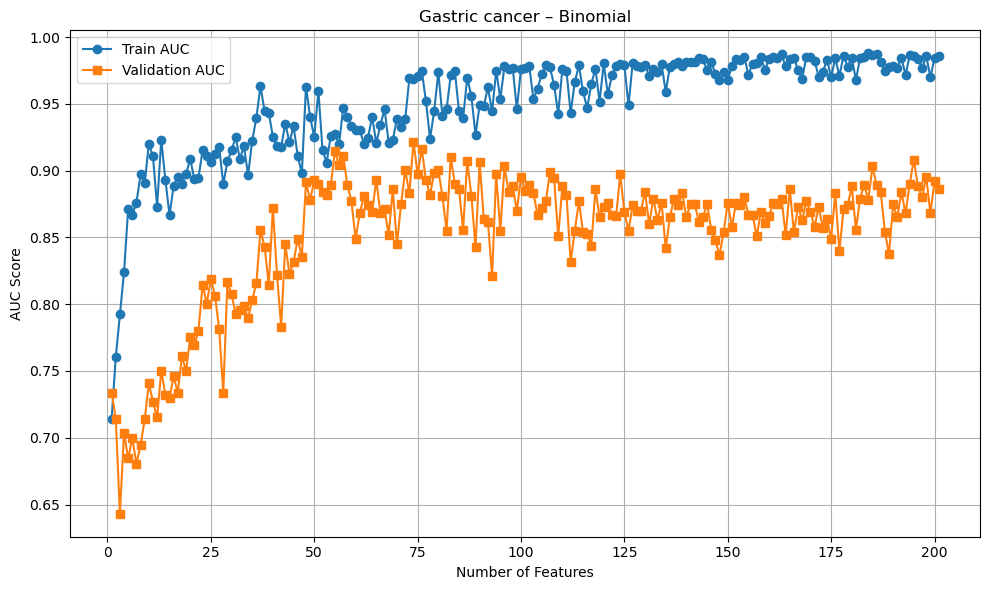

In [137]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Binomial.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Gastric cancer – Binomial")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Binomial.png", dpi=300)
plt.show()

### biomaker分析

In [2]:
import pandas as pd

file_paths = [
    "../ANOVA/Gastric_sample_AnovaSorted_selected20.csv",
    "../Binomial/Gastric_sample_BinomialSorted_selected74.csv",
    "../Fscore/Gastric_sample_FscoreSorted_selected20.csv",
    "../ReliefF/Gastric_sample_ReliefFSorted_selected27.csv"
]
dfs = [pd.read_csv(file_path) for file_path in file_paths]
dfs_info = [df.head() for df in dfs]


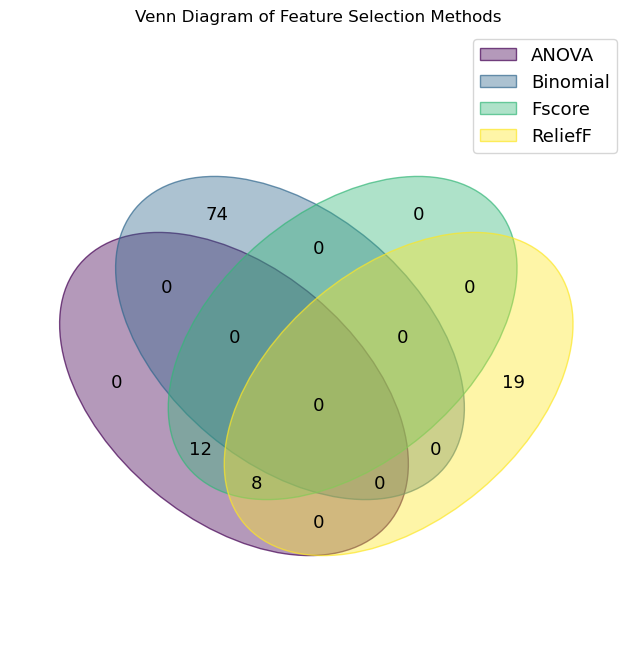

In [3]:
import matplotlib.pyplot as plt
from venn import venn
import pandas as pd

# 加载所有文件
df_anova = dfs[0]
df_binomial = dfs[1]
df_fscore = dfs[2]
df_reliefF = dfs[3]

# 提取每个文件的特征列
anova_features = set(df_anova.columns[1:])
binomial_features = set(df_binomial.columns[1:])
fscore_features = set(df_fscore.columns[1:])
relieff_features = set(df_reliefF.columns[1:])

feature_sets = {
    'ANOVA': anova_features,
    'Binomial': binomial_features,
    'Fscore': fscore_features,
    'ReliefF': relieff_features
}

venn(feature_sets)
plt.title("Venn Diagram of Feature Selection Methods")
plt.show()